# Exploración y verificación de compraventas urbanas

Grupo 4 · Entrega 2 · 4 de noviembre de 2026

Guillermo Prieto, Juan Sebastián Victoria, Ivette Yvonne Campos y Jecika León.

In [ ]:
from pathlib import Path
import json, urllib.request, urllib.parse
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urlencode
from urllib.request import urlopen
import json

URL = "https://www.datos.gov.co/resource/7y2j-43cv.json"
FILTRO_BASE = ("divipola in ('63001','17001','66001') "
               "AND nombre_natujur = 'COMPRAVENTA' "
               "AND upper(tipo_predio_zona) = 'URBANO' "
               "AND year_radica between '2015' and '2023'")
CAMPOS = ['pk','municipio','year_radica','valor','tiene_mas_de_un_valor',
          'divipola','nombre_natujur','tipo_predio_zona']
archivo = Path('datos_fuente_auditados.csv')
if archivo.exists():
    universo = pd.read_csv(archivo, dtype={'pk':str,'divipola':str})
    print('Se utiliza el corte incluido con los soportes.')
else:
    registros = []
    for offset in range(0, 1_000_000, 40_000):
        parametros = {'$select':','.join(CAMPOS), '$where':FILTRO_BASE,
                      '$order':'pk', '$limit':40_000, '$offset':offset}
        with urllib.request.urlopen(URL+'?'+urllib.parse.urlencode(parametros), timeout=180) as r:
            pagina = json.load(r)
        registros.extend(pagina)
        if len(pagina) < 40_000:
            break
    else:
        raise RuntimeError('Se alcanzó el límite de seguridad; revisar la descarga.')
    universo = pd.DataFrame(registros, columns=CAMPOS)
    universo.to_csv(archivo, index=False)
    print('Se descargó un corte nuevo; puede diferir del corte entregado.')
for c in ['year_radica','valor','tiene_mas_de_un_valor']:
    universo[c] = pd.to_numeric(universo[c], errors='coerce')
assert universo.pk.notna().all() and universo.pk.is_unique, 'Revisar claves pk.'
assert universo.year_radica.between(2015,2023).all()
assert set(universo.municipio) == {'ARMENIA','MANIZALES','PEREIRA'}
print('Registros del universo:', len(universo))
datos_piloto = universo.loc[universo.valor.gt(0) & universo.tiene_mas_de_un_valor.eq(0)].copy()
print('Registros monetarios:', len(datos_piloto))
Path('figuras').mkdir(exist_ok=True)


Se descargó un corte nuevo; puede diferir del corte entregado.
Registros del universo: 214190
Registros monetarios: 214036


In [ ]:
#Inclusion de campos adicionales para enriquecer el universo de datos y permitir la inspección de los valores de fecha de radicación.

campos_extra = ["pk", "fecha_radica_texto", "matricula", "orip"]
tamano_pagina = 20_000
registros = []

for offset in range(0, 1_000_000, tamano_pagina):
    parametros = {
        "$select": ",".join(campos_extra),
        "$where": FILTRO_BASE,
        "$order": "pk",
        "$limit": tamano_pagina,
        "$offset": offset,
    }

    with urlopen(f"{URL}?{urlencode(parametros)}", timeout=180) as respuesta:
        pagina = json.load(respuesta)

    registros.extend(pagina)
    if len(pagina) < tamano_pagina:
        break
else:
    raise RuntimeError("Se alcanzó el límite de paginación.")

extra = pd.DataFrame(registros, columns=campos_extra).astype("string")
base = universo.copy()
base["pk"] = base["pk"].astype("string")

enriquecido = base.merge(
    extra,
    on="pk",
    how="left",
    validate="one_to_one",
    indicator="estado_cruce",
)

# Interpretar únicamente los dos formatos observados en la muestra.
texto = enriquecido["fecha_radica_texto"].astype("string").str.strip()
fecha = pd.Series(pd.NaT, index=enriquecido.index, dtype="datetime64[ns]")

formatos = [
    (r"\d{1,2}/\d{1,2}/\d{4}", "%d/%m/%Y"),
    (r"\d{1,2}/\d{1,2}/\d{2}", "%d/%m/%y"),
    (r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}", "%Y-%m-%d %H:%M:%S"),
]

for patron, formato in formatos:
    coincide = texto.str.fullmatch(patron, na=False)
    fecha.loc[coincide] = pd.to_datetime(
        texto.loc[coincide], format=formato, errors="coerce"
    )

anio_corte = pd.to_numeric(enriquecido["year_radica"], errors="coerce")
anio_valido = fecha.dt.year.eq(anio_corte).fillna(False)

enriquecido["fecha_radica"] = fecha.where(anio_valido).dt.normalize()
enriquecido["mes_radica"] = enriquecido["fecha_radica"].dt.month.astype("Int64")

control_fechas = (
    enriquecido.assign(
        fecha_valida=enriquecido["fecha_radica"].notna(),
        anio_distinto=fecha.notna() & ~anio_valido,
    )
    .groupby(["municipio", "year_radica"])
    .agg(
        registros=("pk", "size"),
        fechas_validas=("fecha_valida", "sum"),
        fechas_con_anio_distinto=("anio_distinto", "sum"),
    )
)

control_fechas["fechas_pendientes"] = (
    control_fechas["registros"] - control_fechas["fechas_validas"]
)

display(control_fechas.groupby(level="municipio").sum())
display(control_fechas.loc[control_fechas["fechas_pendientes"].gt(0)])

pendientes = enriquecido["fecha_radica"].isna()
if pendientes.any():
    display(
        enriquecido.loc[
            pendientes, ["municipio", "year_radica", "fecha_radica_texto"]
        ].head(20)
    )

,registros,fechas_validas,fechas_con_anio_distinto,fechas_pendientes
municipio,,,,
ARMENIA,86565,86565,0,0
MANIZALES,66313,66313,0,0
PEREIRA,61312,61312,0,0


,,registros,fechas_validas,fechas_con_anio_distinto,fechas_pendientes
municipio,year_radica,,,,


### Se agrega el IPC a diciembre 2023 a los demás años para hacerlos comparables

In [43]:
# Variación anual del IPC nacional a diciembre, en porcentaje.
ipc_anual_pct = pd.Series({
    2016: 5.75,
    2017: 4.09,
    2018: 3.18,
    2019: 3.80,
    2020: 1.61,
    2021: 5.62,
    2022: 13.12,
    2023: 9.28,
})

anio_base = 2023
factor_por_anio = pd.Series({
    anio: (1 + ipc_anual_pct.loc[anio + 1:anio_base] / 100).prod()
    for anio in range(2015, anio_base + 1)
})

filtro_monetario = (
    enriquecido["valor"].gt(0)
    & enriquecido["tiene_mas_de_un_valor"].eq(0)
)
datos_reales = enriquecido.loc[filtro_monetario].copy()
datos_reales["factor_ipc"] = datos_reales["year_radica"].map(factor_por_anio)

if datos_reales["factor_ipc"].isna().any():
    raise ValueError("Hay años de radicación sin factor de ajuste por IPC.")

datos_reales["valor_cop_dic2023"] = (
    datos_reales["valor"] * datos_reales["factor_ipc"]
)

display(factor_por_anio.rename("factor_a_dic_2023").round(6))

2015    1.564030
2016    1.478988
2017    1.420874
2018    1.377083
2019    1.326669
2020    1.305648
2021    1.236175
2022    1.092800
2023    1.000000
Name: factor_a_dic_2023, dtype: float64

In [44]:
claves = ["municipio", "year_radica"]

actividad = (
    universo.groupby(claves)
    .size()
    .rename("compraventas_universo")
    .to_frame()
)

resumen_monetario = datos_reales.groupby(claves).agg(
    registros_monetarios=("valor", "size"),
    mediana_nominal_cop=("valor", "median"),
    mediana_real_cop=("valor_cop_dic2023", "median"),
    q1_real_cop=("valor_cop_dic2023", lambda valores: valores.quantile(0.25)),
    q3_real_cop=("valor_cop_dic2023", lambda valores: valores.quantile(0.75)),
)

tabla_piloto = actividad.join(resumen_monetario).sort_index()
tabla_piloto["riq_real_cop"] = (
    tabla_piloto["q3_real_cop"] - tabla_piloto["q1_real_cop"]
)

# Calcular la variación dentro de cada municipio y en orden cronológico.
for columna, resultado in {
    "compraventas_universo": "variacion_actividad_pct",
    "mediana_real_cop": "variacion_mediana_real_pct",
}.items():
    tabla_piloto[resultado] = (
        tabla_piloto.groupby(level="municipio")[columna]
        .pct_change(fill_method=None)
        .mul(100)
    )

display(tabla_piloto.reset_index().round(2))

,municipio,year_radica,compraventas_universo,registros_monetarios,mediana_nominal_cop,mediana_real_cop,q1_real_cop,q3_real_cop,riq_real_cop,variacion_actividad_pct,variacion_mediana_real_pct
0,ARMENIA,2015,9075,9072,45104500.0,7.054477e+07,27600520.49,1.338604e+08,1.062598e+08,NaN,NaN
1,ARMENIA,2016,10487,10487,48261848.0,7.137868e+07,35643605.27,1.294907e+08,9.384713e+07,15.56,1.18
2,ARMENIA,2017,9478,9478,57500000.0,8.170026e+07,27380242.42,1.522942e+08,1.249139e+08,-9.62,14.46
3,ARMENIA,2018,9698,9697,56086000.0,7.723507e+07,22033324.64,1.391418e+08,1.171085e+08,2.32,-5.47
4,ARMENIA,2019,8612,8612,70000000.0,9.286685e+07,27860056.45,1.526485e+08,1.247884e+08,-11.20,20.24
5,ARMENIA,2020,8522,8521,80987400.0,1.057411e+08,28724265.14,1.881962e+08,1.594719e+08,-1.05,13.86
6,ARMENIA,2021,10942,10942,77500000.0,9.580359e+07,30904384.00,1.658366e+08,1.349322e+08,28.40,-9.40
7,ARMENIA,2022,10079,10079,81200000.0,8.873536e+07,27320000.00,1.562704e+08,1.289504e+08,-7.89,-7.38
8,ARMENIA,2023,9672,9672,108000000.0,1.080000e+08,52268000.00,1.655000e+08,1.132320e+08,-4.04,21.71
9,MANIZALES,2015,7713,7712,83100000.0,1.299709e+08,73509389.66,2.234803e+08,1.499709e+08,NaN,NaN


## Cobertura y calidad

Se inspeccionan los ocho campos del corte. La ausencia de claves repetidas no demuestra ausencia de inmuebles con varias operaciones. La tasa de conservación monetaria no es una medida integral de calidad.

In [45]:
calidad = pd.DataFrame({'campo':universo.columns,
                        'nulos':universo.isna().sum().values})
display(calidad)
print('Claves pk repetidas:', universo.pk.duplicated().sum())
print('Filas idénticas en los ocho campos:', universo.duplicated().sum())
print('Valor menor o igual a cero:', universo.valor.le(0).sum())
print('Indicador de múltiples valores distinto de cero:', universo.tiene_mas_de_un_valor.ne(0).sum())
cobertura = universo.groupby('municipio').size().to_frame('universo')
cobertura['conservados'] = datos_reales.groupby('municipio').size()
cobertura['excluidos'] = cobertura.universo - cobertura.conservados
cobertura['cobertura_pct'] = 100*cobertura.conservados/cobertura.universo
display(cobertura.round(4))
calidad.to_csv('calidad_campos.csv', index=False)
cobertura.to_csv('cobertura_municipios.csv')


,campo,nulos
0,pk,0
1,municipio,0
2,year_radica,0
3,valor,0
4,tiene_mas_de_un_valor,0
5,divipola,0
6,nombre_natujur,0
7,tipo_predio_zona,0


Claves pk repetidas: 0
Filas idénticas en los ocho campos: 0
Valor menor o igual a cero: 144
Indicador de múltiples valores distinto de cero: 10


,universo,conservados,excluidos,cobertura_pct
municipio,,,,
ARMENIA,86565,86560,5,99.9942
MANIZALES,66313,66295,18,99.9729
PEREIRA,61312,61181,131,99.7863


## Actividad y evolución relativa

Se retoman los indicadores de variación interanual e índice con base 2015 = 100 incorporados en el trabajo del equipo. Las variaciones describen registros, sin probar rentabilidad ni valorización de inmuebles equivalentes.

municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,9072,7712,7031
2016,10487,7187,8238
2017,9478,6761,7086
2018,9697,7363,6170
2019,8612,7709,6363
2020,8521,6210,5798
2021,10942,8410,6897
2022,10079,8581,7375
2023,9672,6362,6223


municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,NaN,NaN,NaN
2016,15.60,-6.81,17.17
2017,-9.62,-5.93,-13.98
2018,2.31,8.90,-12.93
2019,-11.19,4.70,3.13
2020,-1.06,-19.44,-8.88
2021,28.41,35.43,18.95
2022,-7.89,2.03,6.93
2023,-4.04,-25.86,-15.62


municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,100.00,100.00,100.00
2016,115.60,93.19,117.17
2017,104.48,87.67,100.78
2018,106.89,95.47,87.75
2019,94.93,99.96,90.50
2020,93.93,80.52,82.46
2021,120.61,109.05,98.09
2022,111.10,111.27,104.89
2023,106.61,82.49,88.51


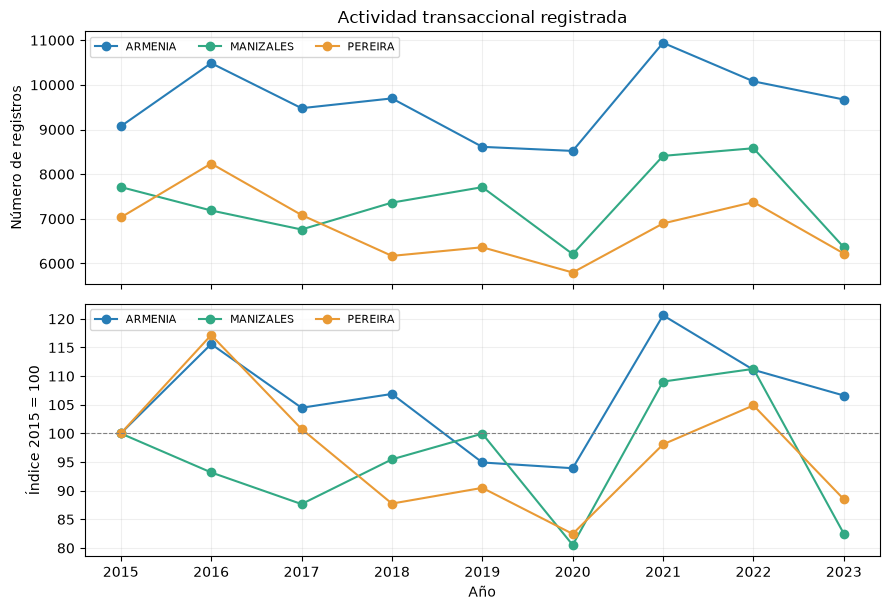

In [46]:
tabla_anual = datos_reales.groupby(['year_radica','municipio']).size().unstack()
variacion_anual = tabla_anual.pct_change(fill_method=None)*100
indice_base_2015 = tabla_anual.div(tabla_anual.loc[2015],axis='columns')*100
display(tabla_anual)
display(variacion_anual.round(2))
display(indice_base_2015.round(2))
fig, ejes = plt.subplots(2,1,figsize=(9,6.2),sharex=True)
colores = ['#277DB6','#32A984','#E99A35']
tabla_anual.plot(ax=ejes[0],marker='o',color=colores)
ejes[0].set_ylabel('Número de registros')
ejes[0].set_title('Actividad transaccional registrada')
indice_base_2015.plot(ax=ejes[1],marker='o',color=colores)
ejes[1].axhline(100,color='gray',ls='--',lw=.8)
ejes[1].set_ylabel('Índice 2015 = 100');ejes[1].set_xlabel('Año')
for ax in ejes:
    ax.grid(alpha=.2);ax.legend(title=None,ncol=3,fontsize=8)
    ax.set_xticks(tabla_anual.index)
fig.tight_layout();fig.savefig('figuras/actividad.png',dpi=200);plt.show()


## Distribución monetaria y señales de revisión

Se calcula la media directamente sobre los registros, sin promediar medias anuales. Las señales de Tukey se definen fuera de Q1 − 1,5·RIQ y Q3 + 1,5·RIQ por municipio. Se conservan en el conjunto; no se interpretan como errores ni irregularidades. El histograma muestra el rango 10³–10¹² COP en escala logarítmica; los valores inferiores a 1.000 COP están fuera de la ventana visual y permanecen en los cálculos.

,municipio,year_radica,mediana_nominal_millones,mediana_real_millones,variacion_real_interanual_pct
0,ARMENIA,2015,45.10,70.54,NaN
1,ARMENIA,2016,48.26,71.38,1.18
2,ARMENIA,2017,57.50,81.70,14.46
3,ARMENIA,2018,56.09,77.24,-5.47
4,ARMENIA,2019,70.00,92.87,20.24
5,ARMENIA,2020,80.99,105.74,13.86
6,ARMENIA,2021,77.50,95.80,-9.40
7,ARMENIA,2022,81.20,88.74,-7.38
8,ARMENIA,2023,108.00,108.00,21.71
9,MANIZALES,2015,83.10,129.97,NaN


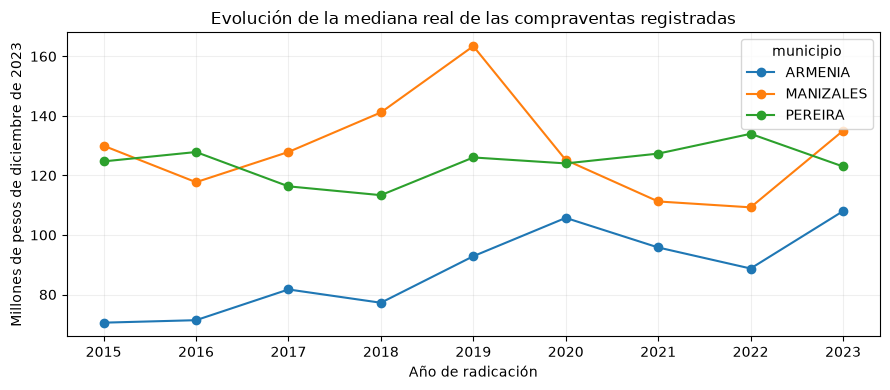

In [47]:
# Medianas en millones de pesos para facilitar la lectura.
medianas = (
    datos_reales
    .groupby(["municipio", "year_radica"])[["valor", "valor_cop_dic2023"]]
    .median()
    .div(1_000_000)
    .rename(columns={
        "valor": "mediana_nominal_millones",
        "valor_cop_dic2023": "mediana_real_millones",
    })
    .sort_index()
)

medianas["variacion_real_interanual_pct"] = (
    medianas.groupby(level="municipio")["mediana_real_millones"]
    .pct_change(fill_method=None)
    .mul(100)
)

display(medianas.reset_index().round(2))

# Comparar la evolución del valor mediano registrado entre ciudades.
ax = medianas["mediana_real_millones"].unstack("municipio").plot(
    figsize=(9, 4),
    marker="o",
    title="Evolución de la mediana real de las compraventas registradas",
)
ax.set_xlabel("Año de radicación")
ax.set_ylabel("Millones de pesos de diciembre de 2023")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Resumen municipal de todo el período 2015–2023 | Millones de COP de diciembre de 2023


,registros,mediana,promedio,minimo,maximo,q1,q3
municipio,,,,,,,
ARMENIA,86560,88.21,131.00,0.0,19725.66,30.00,154.23
MANIZALES,66295,130.82,264.85,0.0,568132.72,49.25,219.54
PEREIRA,61181,124.72,384.02,0.0,537090.40,60.79,208.54


MMediana por municipio y año | Millones de COP de diciembre de 2023


municipio,ARMENIA,MANIZALES,PEREIRA
year_radica,,,
2015,70.54,129.97,124.71
2016,71.38,117.73,127.86
2017,81.70,127.88,116.33
2018,77.24,141.15,113.37
2019,92.87,163.42,126.03
2020,105.74,125.18,124.04
2021,95.80,111.26,127.33
2022,88.74,109.28,133.98
2023,108.00,135.00,123.00


Atípicos por municipio | Límite superior en millones de COP de diciembre de 2023


,atipicos_riq,porcentaje,limite_superior
municipio,,,
ARMENIA,5015,5.79,340.58
MANIZALES,2927,4.42,474.97
PEREIRA,4660,7.62,430.16


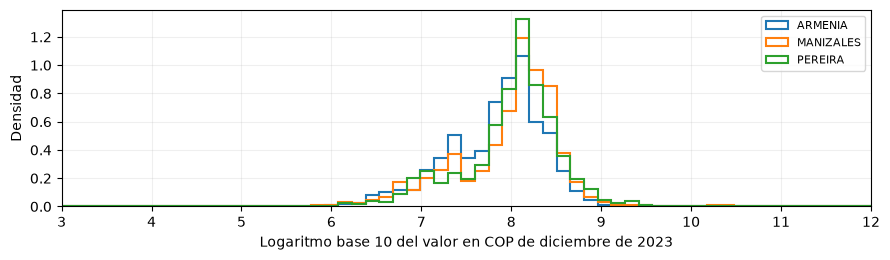

In [48]:
columna_real = "valor_cop_dic2023"
valores_por_municipio = datos_reales.groupby("municipio")[columna_real]

# 1. Resumen monetario: una fila por municipio.
resumen = valores_por_municipio.agg(
    registros="count",
    mediana="median",
    promedio="mean",
    minimo="min",
    maximo="max",
)
resumen["q1"] = valores_por_municipio.quantile(0.25)
resumen["q3"] = valores_por_municipio.quantile(0.75)

print("Resumen municipal de todo el período 2015–2023 | Millones de COP de diciembre de 2023")
display(resumen.assign(**{
    columna: resumen[columna] / 1_000_000
    for columna in ["mediana", "promedio", "minimo", "maximo", "q1", "q3"]
}).round(2))
resumen.to_csv("resumen_monetario_real.csv")

# 2. Mediana anual: una fila por año y una columna por municipio.
tabla_mediana = (
    datos_reales.groupby(["year_radica", "municipio"])[columna_real]
    .median()
    .unstack("municipio")
)

print("MMediana por municipio y año | Millones de COP de diciembre de 2023")
display(tabla_mediana.div(1_000_000).round(2))

# 3. Atípicos de Tukey: una fila por municipio.
filas = []
for municipio, valores in valores_por_municipio:
    q1 = resumen.loc[municipio, "q1"]
    q3 = resumen.loc[municipio, "q3"]
    riq = q3 - q1
    limite_inferior = q1 - 1.5 * riq
    limite_superior = q3 + 1.5 * riq
    fuera_de_limites = (valores < limite_inferior) | (valores > limite_superior)

    filas.append({
        "municipio": municipio,
        "atipicos_riq": int(fuera_de_limites.sum()),
        "porcentaje": 100 * fuera_de_limites.mean(),
        "limite_superior": limite_superior,
    })

atipicos = pd.DataFrame(filas).set_index("municipio")

print("Atípicos por municipio | Límite superior en millones de COP de diciembre de 2023")
display(atipicos.assign(
    limite_superior=atipicos["limite_superior"] / 1_000_000
).round(2))
atipicos.to_csv("valores_extremos_reales.csv")

# 4. Distribución de los valores ajustados.
fig, ax = plt.subplots(figsize=(9, 2.7))

for municipio, valores in valores_por_municipio:
    ax.hist(
        np.log10(valores),
        bins=np.linspace(0, 12, 80),
        density=True,
        histtype="step",
        linewidth=1.5,
        label=municipio,
    )

ax.set_xlabel("Logaritmo base 10 del valor en COP de diciembre de 2023")
ax.set_ylabel("Densidad")
ax.set_xlim(3, 12)
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("figuras/distribucion_real.png", dpi=200)
plt.show()

## Interpretación y conciliación

Entre 2015 y 2023, el número de compraventas urbanas registradas aumentó **6,58 % en Armenia** y disminuyó **17,49 % en Manizales** y **11,40 % en Pereira**. Estos cambios se calcularon sobre las **214.190 compraventas del corte auditado**. Las estadísticas monetarias se calcularon sobre los **214.036 registros** que cumplen el filtro de valor positivo e indicador de múltiples valores igual a cero.

Los valores registrados se expresaron en **millones de pesos de diciembre de 2023**, usando el IPC nacional del DANE y el año de radicación. La comparación entre el primer y el último año del piloto muestra lo siguiente:

| Municipio | Mediana real en 2015 | Mediana real en 2023 | Variación real 2015–2023 |
|---|---:|---:|---:|
| Armenia | 70,54 | 108,00 | +53,09 % |
| Manizales | 129,97 | 135,00 | +3,87 % |
| Pereira | 124,71 | 123,00 | −1,37 % |

Armenia registró el mayor aumento de la mediana real y fue el único municipio con más compraventas en 2023 que en 2015. En Manizales, la mediana real aumentó mientras disminuyó el número de compraventas. En Pereira disminuyeron ambos indicadores. Estos cambios describen el valor mediano de las operaciones registradas y pueden reflejar diferencias en la composición de los inmuebles transados entre años.


In [49]:
# Pruebas de consistencia del corte entregado.
esperados = {"ARMENIA": 86_560, "MANIZALES": 66_295, "PEREIRA": 61_181}

assert len(universo) == 214_190
assert len(datos_reales) == 214_036
assert datos_reales.groupby("municipio").size().to_dict() == esperados
assert datos_reales["pk"].is_unique
assert datos_reales[CAMPOS].isna().sum().sum() == 0

# Medianas nominales del corte, en COP.
medianas_nominales = datos_reales.groupby("municipio")["valor"].median()
assert medianas_nominales.to_dict() == {
    "ARMENIA": 70_000_000,
    "MANIZALES": 99_000_000,
    "PEREIRA": 92_500_000,
}

# Medianas ajustadas del período completo, en COP de diciembre de 2023.
medianas_reales_esperadas = pd.Series({
    "ARMENIA": 88_205_659.62,
    "MANIZALES": 130_822_865.07,
    "PEREIRA": 124_722_388.31,
})

medianas_reales = datos_reales.groupby("municipio")["valor_cop_dic2023"].median()
diferencia = medianas_reales.sub(medianas_reales_esperadas).abs()

assert diferencia.le(0.01).all(), (
    "Las medianas ajustadas difieren de las esperadas para el corte auditado."
)

datos_reales.to_csv("datos_monetarios_ipc_dic2023.csv", index=False)
print("Pruebas del corte entregado y del ajuste por IPC: correctas.")


Pruebas del corte entregado y del ajuste por IPC: correctas.


## Inspeccion de campos de la fuente de datos con el fin de agregar variables que nos permitan realizar predicciones, mejores analisis y documentar el diccionario de datos.

In [50]:
#Inspeccion de campos de la fuente de datos, para documentar el diccionario de datos.

import json
from urllib.request import urlopen

with urlopen("https://www.datos.gov.co/api/views/7y2j-43cv.json", timeout=60) as respuesta:
    metadatos = json.load(respuesta)

campos_fuente = pd.DataFrame(metadatos["columns"])
display(campos_fuente[["name", "fieldName", "dataTypeName"]])

,name,fieldName,dataTypeName
0,PK,pk,text
1,MATRICULA,matricula,text
2,FECHA_RADICA_TEXTO,fecha_radica_texto,text
3,FECHA_APERTURA_TEXTO,fecha_apertura_texto,text
4,YEAR_RADICA,year_radica,text
5,ORIP,orip,text
6,DIVIPOLA,divipola,text
7,DEPARTAMENTO,departamento,text
8,MUNICIPIO,municipio,text
9,TIPO_PREDIO_ZONA,tipo_predio_zona,text


In [51]:
from urllib.parse import urlencode

campos_nuevos = [
    "numero_catastral",
    "numero_catastral_antiguo",
    "matricula",
    "orip",
    "fecha_radica_texto",
]

muestra = (
    universo.sort_values("pk")
    .groupby(["divipola", "year_radica"])
    .head(5)[["pk", "divipola", "municipio", "year_radica"]]
    .copy()
)
muestra["pk"] = muestra["pk"].astype(str)

# Se consultan únicamente las claves del corte auditado.
claves_sql = ",".join(
    "'" + clave.replace("'", "''") + "'" for clave in muestra["pk"]
)
parametros = {
    "$select": ",".join(["pk", *campos_nuevos]),
    "$where": f"pk in ({claves_sql})",
    "$limit": 1000,
}

url = "https://www.datos.gov.co/resource/7y2j-43cv.json"
with urlopen(f"{url}?{urlencode(parametros)}", timeout=60) as respuesta:
    filas = json.load(respuesta)

recuperados = pd.DataFrame(filas, columns=["pk", *campos_nuevos])
recuperados["pk"] = recuperados["pk"].astype(str)

piloto_registro = muestra.merge(
    recuperados,
    on="pk",
    how="left",
    validate="one_to_one",
    indicator=True,
)

display(pd.crosstab(piloto_registro["municipio"], piloto_registro["_merge"]))
display(piloto_registro[campos_nuevos].notna().sum())

_merge,both
municipio,
ARMENIA,45
MANIZALES,45
PEREIRA,45


numero_catastral              0
numero_catastral_antiguo      0
matricula                   135
orip                        135
fecha_radica_texto          135
dtype: int64

In [52]:
catastro = piloto_registro["numero_catastral"].astype("string").str.strip()
catastro_antiguo = (
    piloto_registro["numero_catastral_antiguo"].astype("string").str.strip()
)

# Cobertura preliminar: valores informados, excluyendo blancos y marcadores comunes.
marcadores = ["", "NULL", "NONE", "SIN INFORMACIÓN", "SIN INFORMACION"]
tiene_catastro = catastro.notna() & ~catastro.str.upper().isin(marcadores)
tiene_antiguo = (
    catastro_antiguo.notna() & ~catastro_antiguo.str.upper().isin(marcadores)
)

cobertura = (
    piloto_registro.assign(
        tiene_catastro=tiene_catastro,
        tiene_catastro_antiguo=tiene_antiguo,
        tiene_alguno=tiene_catastro | tiene_antiguo,
    )
    .groupby("municipio")
    .agg(
        muestra=("pk", "size"),
        con_numero_catastral=("tiene_catastro", "sum"),
        con_numero_antiguo=("tiene_catastro_antiguo", "sum"),
        con_algun_numero=("tiene_alguno", "sum"),
    )
)

cobertura["cobertura_pct"] = (
    100 * cobertura["con_algun_numero"] / cobertura["muestra"]
).round(1)

display(cobertura)

,muestra,con_numero_catastral,con_numero_antiguo,con_algun_numero,cobertura_pct
municipio,,,,,
ARMENIA,45,0,0,0,0.0
MANIZALES,45,0,0,0,0.0
PEREIRA,45,0,0,0,0.0


In [53]:
import json
from urllib.parse import urlencode
from urllib.request import urlopen

parametros = {
    "$select": (
        "municipio, count(*) as total, "
        "count(numero_catastral) as con_numero_catastral, "
        "count(numero_catastral_antiguo) as con_numero_antiguo"
    ),
    "$where": FILTRO_BASE,
    "$group": "municipio",
    "$order": "municipio",
}

url = "https://www.datos.gov.co/resource/7y2j-43cv.json"
with urlopen(f"{url}?{urlencode(parametros)}", timeout=120) as respuesta:
    cobertura_fuente = pd.DataFrame(json.load(respuesta))

columnas_conteo = ["total", "con_numero_catastral", "con_numero_antiguo"]
cobertura_fuente[columnas_conteo] = (
    cobertura_fuente[columnas_conteo].apply(pd.to_numeric)
)

display(cobertura_fuente)

,municipio,total,con_numero_catastral,con_numero_antiguo
0,ARMENIA,86565,0,0
1,MANIZALES,66313,0,0
2,PEREIRA,61312,0,0


In [54]:
fechas_texto = piloto_registro["fecha_radica_texto"].astype("string").str.strip()

# Ver ejemplos antes de fijar el formato de lectura.
display(fechas_texto.dropna().drop_duplicates().head(10).to_frame())

# Separar fechas interpretadas y fechas cuyo año coincide con el corte.
fechas = pd.to_datetime(
    fechas_texto,
    format="mixed",
    dayfirst=True,
    errors="coerce",
)

anio_corte = pd.to_numeric(piloto_registro["year_radica"], errors="coerce")
anio_coincide = fechas.dt.year.eq(anio_corte).fillna(False)

display(
    piloto_registro.assign(
        fecha_interpretada=fechas.notna(),
        anio_coincide=anio_coincide,
    )
    .groupby("municipio")
    .agg(
        muestra=("pk", "size"),
        fechas_interpretadas=("fecha_interpretada", "sum"),
        fechas_con_anio_coincidente=("anio_coincide", "sum"),
    )
)

display(
    piloto_registro.loc[
        ~anio_coincide, ["municipio", "year_radica", "fecha_radica_texto"]
    ].head(10)
)

,fecha_radica_texto
0,10/12/2019
1,14/04/2016
2,25/02/22
3,07/03/2018
4,29/10/2020
5,15/05/2018
6,14/02/2017
7,03/06/2020
8,21/05/2015
9,09/06/2021


,muestra,fechas_interpretadas,fechas_con_anio_coincidente
municipio,,,
ARMENIA,45,45,45
MANIZALES,45,45,45
PEREIRA,45,45,45


,municipio,year_radica,fecha_radica_texto


Se realizó la verificación de campos y se incluyeron al principio de la exploración. Se trató de buscar numero catastral con el fin de buscar datos de metros cuadrados pero no se encontró nada en la fuente de datos.